# Phân cụm seller v3: EDA, K-Means, GMM, DBSCAN

Notebook này dùng bộ đặc trưng v3 do leader đề xuất ngày 28/11/2026, chạy cả 3 thuật toán trên **cùng một ma trận** để so sánh.

So với bộ 12 cột của Tzy (v2):

| Thay đổi | Đặc trưng | Lý do |
|---|---|---|
| Bỏ | `cancel_rate` | 88% seller bằng 0, một mình tạo ra cụm 55 seller |
| Bỏ | `repeat_customer_rate` | 84% seller bằng 0, gần như không tách cụm |
| Bỏ | `avg_order_value` | Tương quan 0,88 với `price_index`, giữ `price_index` vì có ý nghĩa so với ngành |
| Thêm | `price_index` | Giá seller so với giá trung bình ngành |
| Thêm | `freight_per_item` | Phí vận chuyển trên mỗi món |
| Bỏ | `hot_score` | Trung vị gần như bằng nhau giữa các cụm, không giúp tách cụm; bỏ đi silhouette tăng |
| Không thêm | `interstate_rate` | Spearman 0,70 với `avg_ship_distance_km`; giữ cả hai làm vận chuyển chiếm quá nhiều trọng số |

Kết quả: 10 đặc trưng. Hai cột `hot_score`, `interstate_rate` vẫn dùng để mô tả cụm ở mục 8.

Đầu vào: `artifacts/seller_segmentation_v2/seller_features.csv` (đặc trưng thô, chưa scale) do `mining/seller_features_extended.py` sinh ra. Đầu ra: `artifacts/seller_clustering_v3/`.

In [1]:
import json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INPUT = ROOT / "artifacts/seller_segmentation_v2/seller_features.csv"
OUT = ROOT / "artifacts/seller_clustering_v3"
OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
FEATURES = ["order_count", "recency_days", "tenure_days", "late_delivery_rate", "review_score_mean",
            "category_count", "avg_ship_distance_km", "delivery_days_mean", "price_index", "freight_per_item"]
# tenure_days không log: phân phối gần đều (skew 0,08), log1p làm lệch trái (-1,06)
LOG1P = ["order_count", "recency_days", "delivery_days_mean", "category_count",
         "avg_ship_distance_km", "price_index", "freight_per_item"]
DROPPED = ["cancel_rate", "repeat_customer_rate", "avg_order_value", "hot_score", "interstate_rate"]
K_RANGE = range(2, 11)
MIN_SHARE = 0.02          # cụm nhỏ hơn 2% cohort bị coi là cụm ngoại lệ
K_KMEANS = 5              # k chốt cho K-Means vì lý do nghiệp vụ; mục 4 kiểm tra lại bằng metric
DESCRIBE = ["total_sales", "avg_order_value", "hot_score", "interstate_rate", "cancel_rate", "repeat_customer_rate",
            "category_hhi", "n_customer_states", "orders_per_active_month"]

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 72   # hình inline nhỏ cho notebook nhẹ; file PNG lưu ở dpi 120
pd.set_option("display.width", 200, "display.max_columns", 40)
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight", dpi=120)
    plt.show()

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
versions

{'python': '3.14.6',
 'numpy': '2.5.1',
 'pandas': '3.0.5',
 'scikit-learn': '1.9.0',
 'matplotlib': '3.11.1',
 'seaborn': '0.13.2'}

## 1. Đọc dữ liệu và chọn cohort

Mỗi dòng là một seller có ít nhất 1 đơn `delivered`. Cờ `model_eligible` đánh dấu seller có **từ 3 đơn delivered trở lên**; chỉ nhóm này vào mô hình, vì tỷ lệ và trung bình tính trên 1-2 đơn rất nhiễu.

In [2]:
assert INPUT.exists(), (f"Thiếu {INPUT}. Chạy notebooks/seller_segmentation_features_v2.ipynb "
                        "hoặc mining/seller_features_extended.py trước.")
raw = pd.read_csv(INPUT)
assert raw["seller_id"].is_unique
missing_cols = [c for c in FEATURES + DROPPED + DESCRIBE if c not in raw]
assert not missing_cols, missing_cols
df = raw[raw["model_eligible"]].reset_index(drop=True)
print(f"Tất cả seller có đơn delivered: {len(raw):,}; cohort mô hình: {len(df):,}; số cột: {raw.shape[1]}")

g = raw.assign(nhom=np.where(raw["model_eligible"], ">= 3 đơn", "< 3 đơn")).groupby("nhom")
cohort = g.agg(so_seller=("seller_id", "size"), tong_doanh_so=("total_sales", "sum"), don_trung_vi=("order_count", "median"))
cohort["ty_le_seller"] = cohort["so_seller"] / cohort["so_seller"].sum()
cohort["ty_le_doanh_so"] = cohort["tong_doanh_so"] / cohort["tong_doanh_so"].sum()
cohort.round(4)

Tất cả seller có đơn delivered: 2,970; cohort mô hình: 2,129; số cột: 82


,so_seller,tong_doanh_so,don_trung_vi,ty_le_seller,ty_le_doanh_so
nhom,,,,,
< 3 đơn,841,264775.66,1.0,0.2832,0.02
>= 3 đơn,2129,12956722.45,12.0,0.7168,0.98


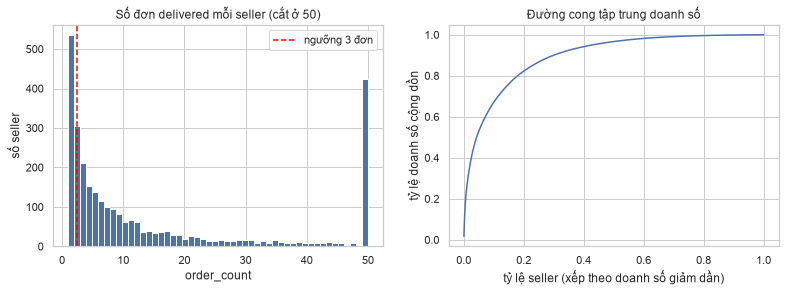

Seller có 1 đơn: 18.0%; 20% seller lớn nhất chiếm 82.3% doanh số


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
oc = raw["order_count"].clip(upper=50)
ax[0].hist(oc, bins=50, color="#4C72B0")
ax[0].axvline(2.5, color="red", ls="--", label="ngưỡng 3 đơn")
ax[0].set(title="Số đơn delivered mỗi seller (cắt ở 50)", xlabel="order_count", ylabel="số seller"); ax[0].legend()
s = raw.sort_values("total_sales", ascending=False)["total_sales"]
ax[1].plot(np.arange(1, len(s) + 1) / len(s), s.cumsum() / s.sum())
ax[1].set(title="Đường cong tập trung doanh số", xlabel="tỷ lệ seller (xếp theo doanh số giảm dần)", ylabel="tỷ lệ doanh số cộng dồn")
save(fig, "eda_cohort.png")
top20 = s.head(int(len(s) * 0.2)).sum() / s.sum()
print(f"Seller có 1 đơn: {(raw.order_count == 1).mean():.1%}; 20% seller lớn nhất chiếm {top20:.1%} doanh số")

## 2. EDA

### 2.1. Giá trị thiếu

Kiểm tra trên cohort mô hình, mọi cột số. Các cột thiếu nhiều (marketing, tăng trưởng) không dùng trong mô hình.

In [4]:
num = df.select_dtypes("number")
miss = num.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].to_frame("ty_le_thieu")
miss["trong_mo_hinh"] = miss.index.isin(FEATURES)
print(f"{len(miss)} / {num.shape[1]} cột số có giá trị thiếu")
miss.round(4)

6 / 69 cột số có giá trị thiếu


,ty_le_thieu,trong_mo_hinh
declared_monthly_revenue,0.8826,False
days_late_mean,0.4392,False
sales_growth,0.3814,False
avg_photos,0.0075,False
avg_description_len,0.0075,False
growth_exposure,0.0005,False


### 2.2. Thống kê mô tả 12 đặc trưng (thang gốc)

In [5]:
def profile_stats(frame, cols):
    rows = {}
    for c in cols:
        s = frame[c].astype(float)
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows[c] = {"mean": s.mean(), "std": s.std(), "min": s.min(), "p25": q1, "median": s.median(), "p75": q3,
                   "max": s.max(), "skew": s.skew(), "zero_share": (s == 0).mean(),
                   "mode_share": s.round(6).value_counts(normalize=True).iloc[0],
                   "iqr_outlier_share": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean(),
                   "missing": s.isna().sum()}
    return pd.DataFrame(rows).T

stats_raw = profile_stats(df, FEATURES)
stats_raw.to_csv(OUT / "feature_stats_raw.csv")
stats_raw.round(3)

,mean,std,min,p25,median,p75,max,skew,zero_share,mode_share,iqr_outlier_share,missing
order_count,45.407,122.278,3.000,6.000,12.000,37.000,1819.000,8.145,0.000,0.099,0.122,0.0
recency_days,96.775,134.679,1.000,11.000,28.000,128.000,695.000,1.816,0.000,0.041,0.102,0.0
tenure_days,338.958,191.244,10.000,162.000,329.000,519.000,714.000,0.080,0.000,0.014,0.000,0.0
late_delivery_rate,0.066,0.095,0.000,0.000,0.033,0.096,0.667,2.460,0.439,0.439,0.065,0.0
review_score_mean,4.182,0.506,1.000,3.955,4.245,4.500,5.000,-1.220,0.000,0.063,0.034,0.0
category_count,2.574,2.377,1.000,1.000,2.000,3.000,27.000,3.378,0.000,0.390,0.060,0.0
avg_ship_distance_km,606.898,295.144,8.522,417.365,564.108,733.408,2565.123,1.556,0.000,0.000,0.037,0.0
delivery_days_mean,12.032,4.993,3.204,8.933,11.378,14.033,66.755,2.474,0.000,0.000,0.038,0.0
price_index,1.488,2.019,0.103,0.541,0.924,1.549,25.807,5.246,0.000,0.001,0.092,0.0
freight_per_item,22.669,16.381,7.390,15.147,18.418,24.200,308.337,6.171,0.000,0.001,0.083,0.0


Đọc bảng: `skew` lớn hơn 1 là lệch phải mạnh, cần `log1p`. `mode_share` là tỷ lệ seller có cùng một giá trị; cột có `mode_share` cao (nhiều số 0) dễ làm K-Means tách riêng vài seller khác 0 thành một cụm.

### 2.3. Các đặc trưng bị bỏ

,mean,median,max,skew,zero_share,mode_share
cancel_rate,0.007,0.000,0.385,6.405,0.883,0.883
repeat_customer_rate,0.007,0.000,0.500,8.764,0.841,0.841
avg_order_value,179.386,109.070,6018.750,8.148,0.000,0.001
hot_score,0.043,0.042,0.093,0.300,0.000,0.050
interstate_rate,0.655,0.667,1.000,-0.328,0.018,0.131


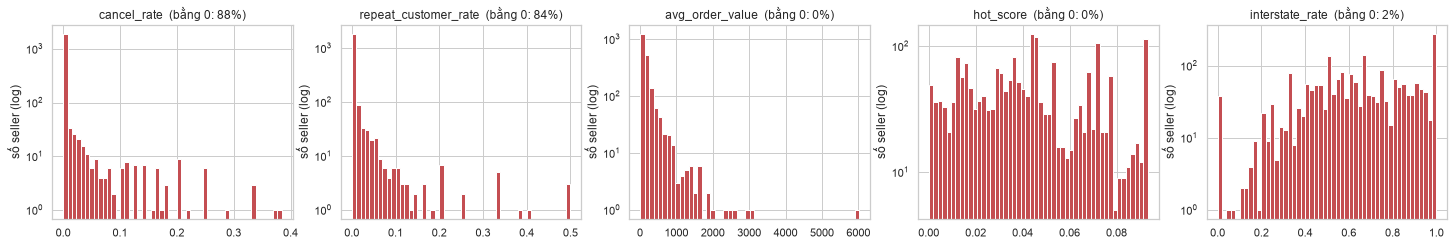

Spearman avg_order_value và price_index: 0.902
Spearman interstate_rate và avg_ship_distance_km: 0.698


In [6]:
stats_drop = profile_stats(df, DROPPED)
display(stats_drop[["mean", "median", "max", "skew", "zero_share", "mode_share"]].round(3))
fig, ax = plt.subplots(1, len(DROPPED), figsize=(5 * len(DROPPED), 3.5))
for a, c in zip(ax, DROPPED):
    a.hist(df[c], bins=50, color="#C44E52")
    a.set(title=f"{c}  (bằng 0: {(df[c] == 0).mean():.0%})", yscale="log", ylabel="số seller (log)")
save(fig, "eda_dropped_features.png")
sp = df[["avg_order_value", "price_index", "interstate_rate", "avg_ship_distance_km"]].corr("spearman")
print(f"Spearman avg_order_value và price_index: {sp.loc['avg_order_value', 'price_index']:.3f}")
print(f"Spearman interstate_rate và avg_ship_distance_km: {sp.loc['interstate_rate', 'avg_ship_distance_km']:.3f}")

### 2.4. Phân phối trước và sau `log1p`

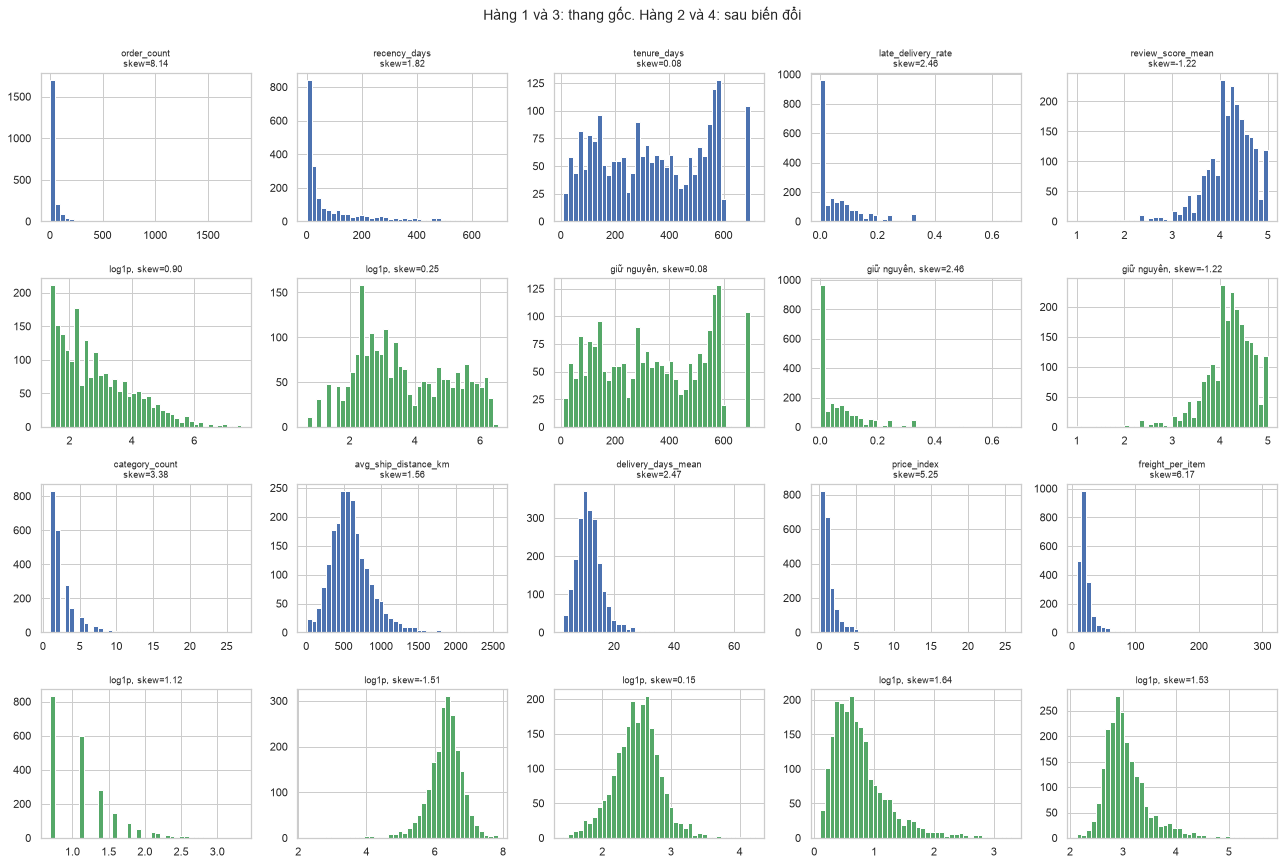

In [7]:
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for i, c in enumerate(FEATURES):
    a_raw, a_tr = axes[(i // 5) * 2, i % 5], axes[(i // 5) * 2 + 1, i % 5]
    s = df[c].dropna()
    a_raw.hist(s, bins=40, color="#4C72B0"); a_raw.set_title(f"{c}\nskew={s.skew():.2f}", fontsize=9)
    t = np.log1p(s) if c in LOG1P else s
    a_tr.hist(t, bins=40, color="#55A868")
    a_tr.set_title(("log1p, " if c in LOG1P else "giữ nguyên, ") + f"skew={t.skew():.2f}", fontsize=9)
fig.suptitle("Hàng 1 và 3: thang gốc. Hàng 2 và 4: sau biến đổi", y=1.0)
fig.tight_layout()
save(fig, "eda_distributions.png")

### 2.5. Tương quan giữa các đặc trưng

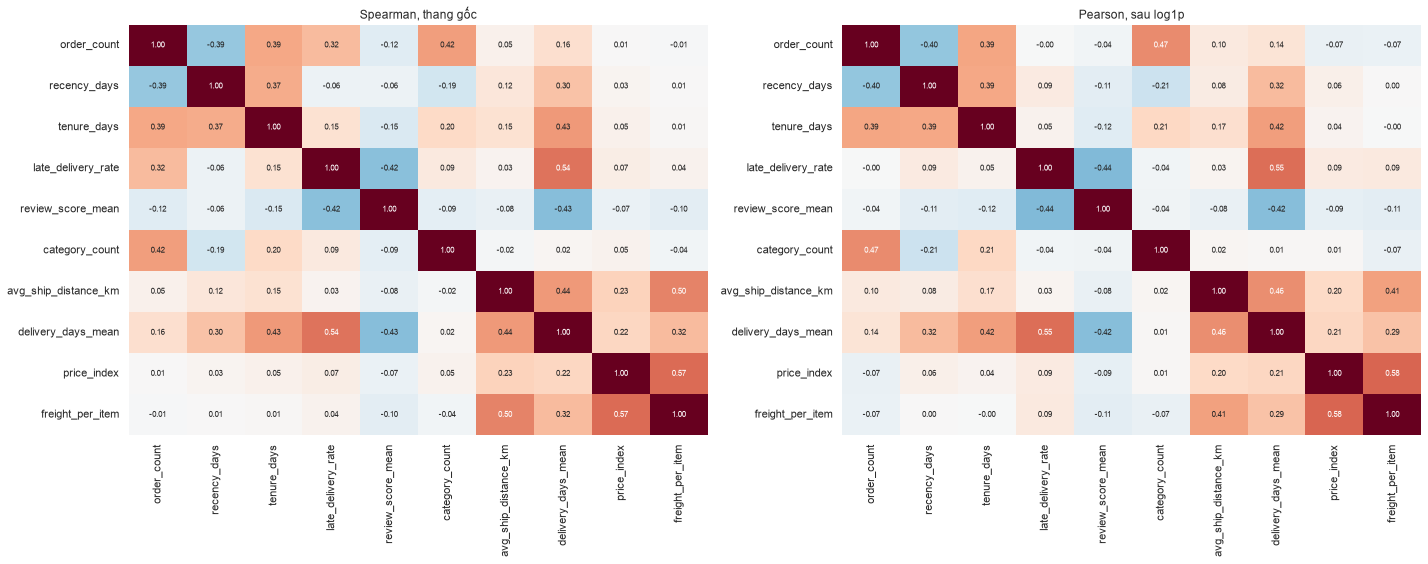

,feature_a,feature_b,spearman,pearson_sau_log1p
1,price_index,freight_per_item,0.565,0.584
0,late_delivery_rate,delivery_days_mean,0.540,0.555


In [8]:
T = df[FEATURES].astype(float).fillna(df[FEATURES].median())
for c in LOG1P:
    T[c] = np.log1p(T[c])
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
for a, (name, m) in zip(ax, [("Spearman, thang gốc", df[FEATURES].corr("spearman")), ("Pearson, sau log1p", T.corr())]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=a, cbar=False, annot_kws={"size": 8})
    a.set_title(name)
fig.tight_layout()
save(fig, "eda_correlation.png")

# Spearman không đổi khi log1p (biến đổi đơn điệu), nên dùng chung tiêu chí với mục 2.6
sc, pc = df[FEATURES].corr("spearman"), T.corr()
pairs = [(a, b, sc.loc[a, b], pc.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(sc.loc[a, b]) >= 0.5]
pairs = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman", "pearson_sau_log1p"])
pairs = pairs.sort_values("spearman", key=abs, ascending=False)
assert sc.where(~np.eye(len(FEATURES), dtype=bool)).abs().max().max() < 0.75, "có cặp |Spearman| >= 0,75"
pairs.round(3)

Tiêu chí loại cột trùng ý: |Spearman| ≥ 0,75, dùng chung cho mục này và mục 2.6. Spearman tính trên thứ hạng nên không đổi khi `log1p`. Các cặp trong bảng (|Spearman| ≥ 0,5) vẫn giữ vì đo các ý khác nhau.

### 2.6. Sàng lọc các đặc trưng chưa dùng

Mọi cột số còn lại trong bảng đặc trưng, so với 12 cột đã chọn. Phân loại tự động: trùng ý nếu |Spearman| ≥ 0,75 với một cột đã chọn; lệch nếu `mode_share` ≥ 0,5 hoặc |skew| > 5; còn lại là ứng viên.

In [9]:
skip = set(FEATURES) | {"model_eligible", "has_marketing_profile", "is_sp"}
cands = [c for c in df.select_dtypes("number").columns if c not in skip]
sp = df[FEATURES + cands].corr("spearman")
rows = []
for c in cands:
    s = df[c].astype(float)
    if s.nunique(dropna=True) <= 1:
        rows.append((c, s.isna().mean(), np.nan, np.nan, np.nan, "", "hằng số"))
        continue
    r = sp.loc[c, FEATURES].abs()
    mode = s.round(6).value_counts(normalize=True).iloc[0]
    if r.max() >= 0.75:
        why = f"trùng ý với {r.idxmax()}"
    elif mode >= 0.5 or abs(s.skew()) > 5:
        why = "lệch hoặc nhiều giá trị lặp"
    else:
        why = "ứng viên"
    rows.append((c, s.isna().mean(), s.skew(), mode, r.max(), r.idxmax(), why))
screen = pd.DataFrame(rows, columns=["feature", "missing", "skew", "mode_share", "max_abs_spearman", "closest", "phan_loai"])
screen = screen.sort_values(["phan_loai", "max_abs_spearman"], ascending=[True, False])
screen.to_csv(OUT / "unused_feature_screening.csv", index=False)
print(screen["phan_loai"].str.replace(r"trùng ý với .*", "trùng ý", regex=True).value_counts().to_string())
screen.round(3)

phan_loai
trùng ý                        24
ứng viên                       19
lệch hoặc nhiều giá trị lặp    14
hằng số                         2


,feature,missing,skew,mode_share,max_abs_spearman,closest,phan_loai
43,distance_coverage,0.000,NaN,NaN,NaN,,hằng số
58,declared_monthly_revenue,0.883,NaN,NaN,NaN,,hằng số
34,delivery_days_std,0.000,5.136,0.000,0.720,delivery_days_mean,lệch hoặc nhiều giá trị lặp
21,sales_growth,0.381,8.680,0.190,0.591,recency_days,lệch hoặc nhiều giá trị lặp
26,market_share_in_cat,0.000,6.385,0.002,0.578,order_count,lệch hoặc nhiều giá trị lặp
9,review_coverage,0.000,-7.303,0.825,0.443,order_count,lệch hoặc nhiều giá trị lặp
48,repeat_customer_rate,0.000,8.764,0.841,0.419,order_count,lệch hoặc nhiều giá trị lặp
52,voucher_rate,0.000,3.409,0.543,0.418,order_count,lệch hoặc nhiều giá trị lặp
12,undelivered_rate,0.000,4.733,0.713,0.394,order_count,lệch hoặc nhiều giá trị lặp
36,days_late_mean,0.439,5.395,0.060,0.325,delivery_days_mean,lệch hoặc nhiều giá trị lặp


### 2.7. Biến phân loại (chỉ dùng mô tả cụm)

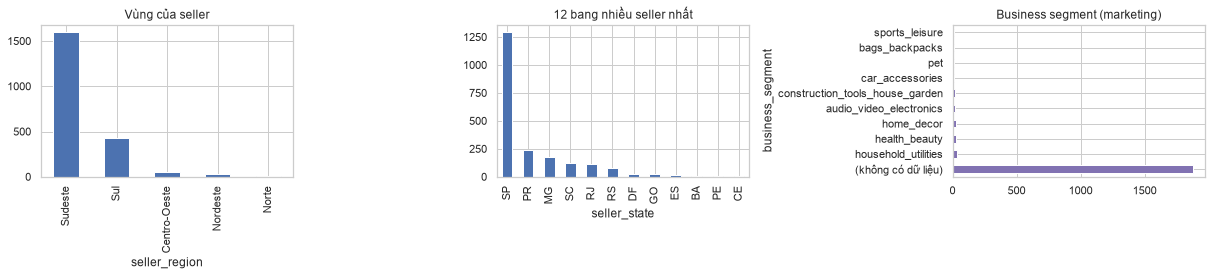

SP chiếm 60.8% seller; có dữ liệu marketing: 11.7%


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["seller_region"].value_counts().plot.bar(ax=ax[0], color="#4C72B0", title="Vùng của seller")
df["seller_state"].value_counts().head(12).plot.bar(ax=ax[1], color="#4C72B0", title="12 bang nhiều seller nhất")
df["business_segment"].fillna("(không có dữ liệu)").value_counts().head(10).plot.barh(ax=ax[2], color="#8172B2", title="Business segment (marketing)")
fig.tight_layout()
save(fig, "eda_categorical.png")
print(f"SP chiếm {(df.seller_state == 'SP').mean():.1%} seller; có dữ liệu marketing: {df.has_marketing_profile.mean():.1%}")

### 2.8. Quan hệ giữa một số cặp đặc trưng

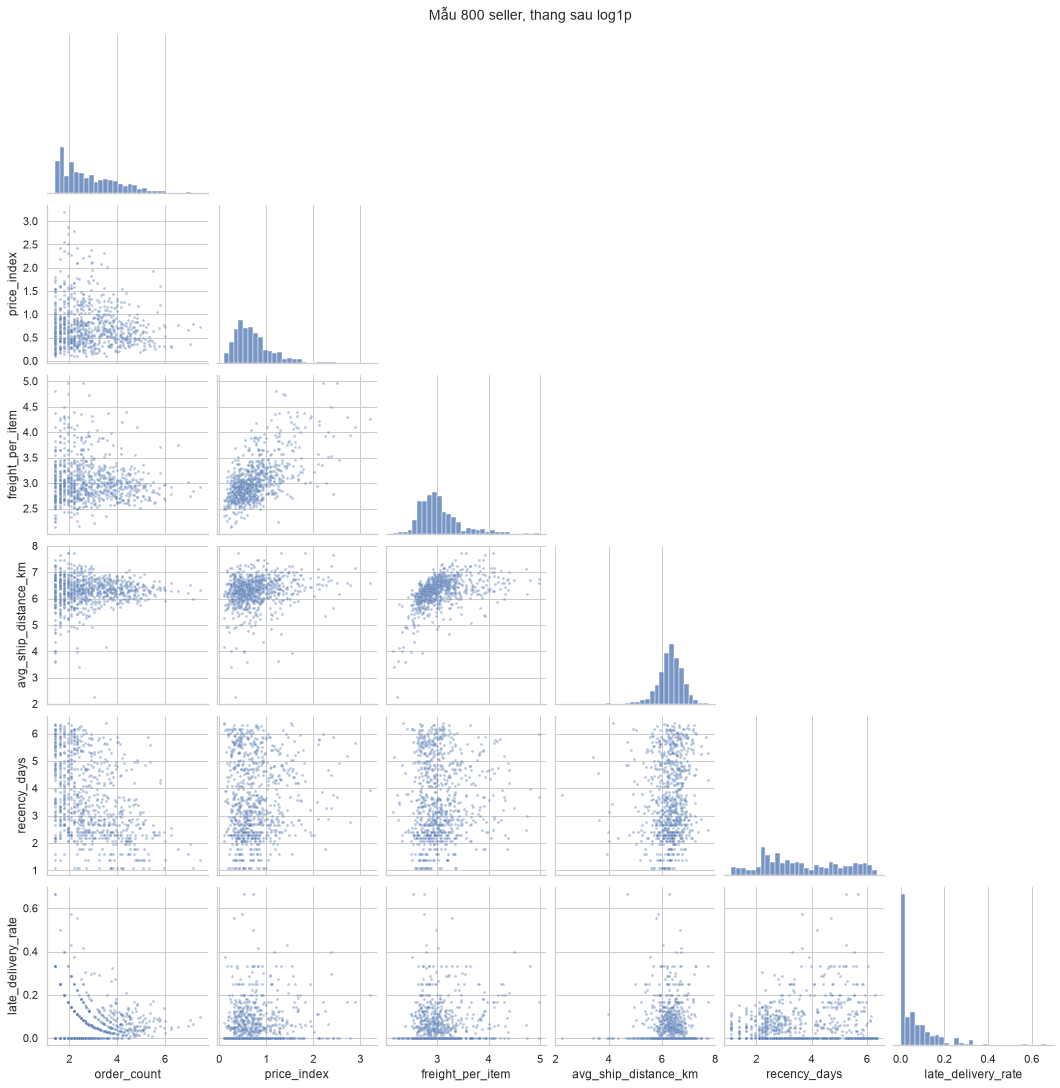

In [11]:
pp = T[["order_count", "price_index", "freight_per_item", "avg_ship_distance_km", "recency_days", "late_delivery_rate"]]
g = sns.pairplot(pp.sample(800, random_state=RANDOM_STATE), corner=True, plot_kws={"s": 8, "alpha": 0.4}, diag_kws={"bins": 30})
g.fig.suptitle("Mẫu 800 seller, thang sau log1p", y=1.01)
g.fig.savefig(OUT / "eda_pairplot.png", bbox_inches="tight", dpi=110)
plt.show()

## 3. Tiền xử lý

1. Điền thiếu bằng median của cohort.
2. `log1p` cho 7 cột lệch phải (danh sách `LOG1P`).
3. `StandardScaler` cho cả 10 cột.

Không xóa hay cắt ngoại lệ: DBSCAN sẽ cho thấy các điểm ngoại lệ ở mục 6.

In [12]:
Xraw = df[FEATURES].astype(float)
medians = Xraw.median()
Xt = Xraw.fillna(medians)
for c in LOG1P:
    assert (Xt[c] >= 0).all(), c
    Xt[c] = np.log1p(Xt[c])
scaler = StandardScaler().fit(Xt)
X = scaler.transform(Xt)
assert np.isfinite(X).all()
assert np.allclose(X.mean(0), 0, atol=1e-9) and np.allclose(X.std(0), 1, atol=1e-9)
back = scaler.inverse_transform(X)
assert np.allclose(back, Xt.to_numpy())

pd.DataFrame(X, columns=FEATURES).assign(seller_id=df["seller_id"])[["seller_id"] + FEATURES].to_csv(OUT / "model_input.csv", index=False)
prep = {"features": FEATURES, "log1p": LOG1P, "dropped_from_v2": DROPPED, "n_sellers": len(df),
        "missing_filled": Xraw.isna().sum().to_dict(), "median": medians.to_dict(),
        "scaler_mean": dict(zip(FEATURES, scaler.mean_)), "scaler_scale": dict(zip(FEATURES, scaler.scale_)),
        "random_state": RANDOM_STATE, "versions": versions}
(OUT / "preprocessing.json").write_text(json.dumps(prep, indent=2, ensure_ascii=False), encoding="utf-8")
print("Ma trận:", X.shape, "| ô đã điền median:", int(Xraw.isna().sum().sum()))

Ma trận: (2129, 10) | ô đã điền median: 0


In [13]:
def scores(labels):
    """Metric trên các điểm không phải nhiễu (label >= 0)."""
    labels = np.asarray(labels)
    m = labels >= 0
    k = len(np.unique(labels[m]))
    out = {"n_clusters": k, "noise_share": 1 - m.mean()}
    if k < 2:
        return out | {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan, "min_cluster_share": np.nan}
    sizes = np.unique(labels[m], return_counts=True)[1]
    return out | {"silhouette": silhouette_score(X[m], labels[m]), "davies_bouldin": davies_bouldin_score(X[m], labels[m]),
                  "calinski_harabasz": calinski_harabasz_score(X[m], labels[m]), "min_cluster_share": sizes.min() / len(labels)}

def relabel(labels):
    """Đánh số lại cụm theo tổng doanh số giảm dần để tên cụm ổn định giữa các lần chạy; giữ -1 là nhiễu."""
    labels = np.asarray(labels)
    sales = pd.Series(df["total_sales"].to_numpy()).groupby(labels).sum().drop(-1, errors="ignore")
    order = {old: new for new, old in enumerate(sales.sort_values(ascending=False).index)}
    return np.array([order.get(l, -1) for l in labels])

## 4. K-Means

Quét k từ 2 đến 10 với `n_init=30`. k được chốt là 5 vì lý do nghiệp vụ: mỗi phân khúc ứng với một chính sách riêng (mục 9). Bảng dưới kiểm tra lại bằng metric: nếu k=5 không có silhouette lớn nhất trong các k có cụm nhỏ nhất ≥ 2% cohort, cell sẽ in cảnh báo. Elbow dùng để đối chiếu.

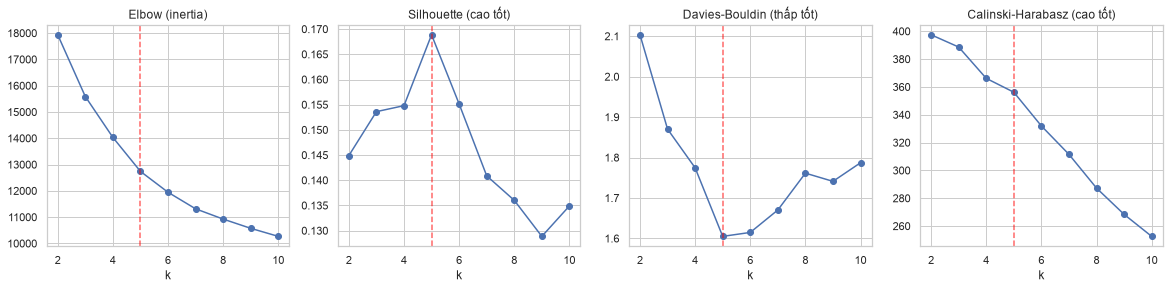

Silhouette lớn nhất (cụm >= 2%): k = 5; K_KMEANS = 5


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,2,17937.6683,0.1449,2.1036,397.5104,0.4115
1,3,15589.6699,0.1536,1.8704,388.6837,0.2842
2,4,14034.6026,0.1548,1.7746,366.1835,0.1822
3,5,12741.9388,0.1689,1.6052,356.2268,0.1010
4,6,11948.2322,0.1551,1.6150,331.9750,0.0944
5,7,11318.7254,0.1409,1.6704,311.5640,0.0907
6,8,10927.7342,0.1360,1.7615,287.3209,0.0432
7,9,10576.4002,0.1289,1.7412,268.4376,0.0451
8,10,10270.2401,0.1349,1.7872,252.6271,0.0310


In [14]:
km_rows, km_models = [], {}
for k in K_RANGE:
    m = KMeans(k, n_init=30, random_state=RANDOM_STATE).fit(X)
    km_models[k] = m
    km_rows.append({"k": k, "inertia": m.inertia_} | scores(m.labels_))
km_metrics = pd.DataFrame(km_rows).drop(columns=["n_clusters", "noise_share"])
km_metrics.to_csv(OUT / "kmeans_metrics.csv", index=False)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, col, title in zip(ax, ["inertia", "silhouette", "davies_bouldin", "calinski_harabasz"],
                         ["Elbow (inertia)", "Silhouette (cao tốt)", "Davies-Bouldin (thấp tốt)", "Calinski-Harabasz (cao tốt)"]):
    a.plot(km_metrics["k"], km_metrics[col], "o-")
    a.axvline(K_KMEANS, color="red", ls="--", alpha=0.6)
    a.set(title=title, xlabel="k")
save(fig, "kmeans_selection.png")

ok = km_metrics[km_metrics["min_cluster_share"] >= MIN_SHARE]
k_rule = int(ok.loc[ok["silhouette"].idxmax(), "k"])
print(f"Silhouette lớn nhất (cụm >= 2%): k = {k_rule}; K_KMEANS = {K_KMEANS}")
if k_rule != K_KMEANS:
    print("CẢNH BÁO: metric không ủng hộ K_KMEANS, cần xem lại lý do chọn k ở mục 9")
km_metrics.round(4)

Ổn định qua 10 seed: ARI nhỏ nhất 0.9839, trung bình 0.9964
Số seller mỗi cụm: [539, 274, 526, 575, 215]


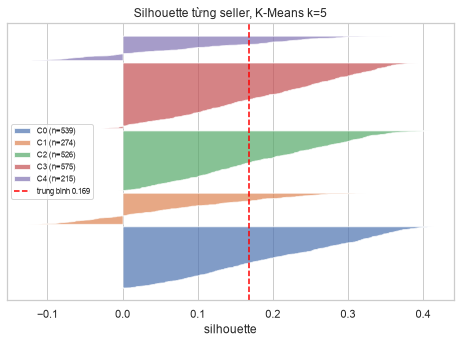

Tỷ lệ seller có silhouette âm theo cụm: {0: 0.004, 1: 0.281, 2: 0.006, 3: 0.037, 4: 0.288}


In [15]:
km = km_models[K_KMEANS]
km_labels = relabel(km.labels_)
aris = [adjusted_rand_score(km.labels_, KMeans(K_KMEANS, n_init=30, random_state=s).fit_predict(X)) for s in range(10)]
print(f"Ổn định qua 10 seed: ARI nhỏ nhất {min(aris):.4f}, trung bình {np.mean(aris):.4f}")
print("Số seller mỗi cụm:", np.bincount(km_labels).tolist())

sil = silhouette_samples(X, km_labels)
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in range(K_KMEANS):
    v = np.sort(sil[km_labels == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7, label=f"C{c} (n={len(v)})")
    y0 += len(v) + 20
ax.axvline(sil.mean(), color="red", ls="--", label=f"trung bình {sil.mean():.3f}")
ax.set(title=f"Silhouette từng seller, K-Means k={K_KMEANS}", xlabel="silhouette", yticks=[]); ax.legend(fontsize=8)
save(fig, "kmeans_silhouette_samples.png")
print("Tỷ lệ seller có silhouette âm theo cụm:", pd.Series(sil < 0).groupby(km_labels).mean().round(3).to_dict())

## 5. GMM

Quét số thành phần 2 đến 10 với 4 kiểu hiệp phương sai (`full`, `tied`, `diag`, `spherical`), `n_init=5`. Chọn theo BIC nhỏ nhất trong các mô hình có cụm nhỏ nhất ≥ 2% (nhãn lấy theo xác suất hậu nghiệm lớn nhất).

BIC = −2 log-likelihood + số tham số × ln(n). Với `full`, mỗi thành phần có 10 trung bình và 55 phần tử hiệp phương sai, nên thêm một cụm tốn 66 tham số và BIC phạt nặng số cụm. BIC đo mức khớp phân phối chứ không đo mức tách cụm, nên mô hình có BIC tốt vẫn có thể có silhouette thấp.

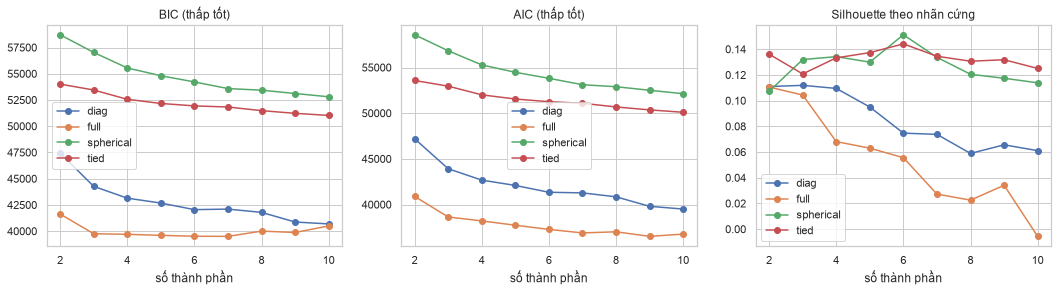

BIC nhỏ nhất (cụm >= 2%): covariance=full, k=7
BIC nhỏ nhất không ràng buộc: {'covariance': 'full', 'k': 7}


,covariance,k,bic,aic,mean_max_proba,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
5,full,7,39508.5945,36897.7636,0.9256,7,0.0273,2.7454,146.6703,0.0578
4,full,6,39521.5813,37284.5353,0.9310,6,0.0556,2.5292,173.4660,0.0747
3,full,5,39603.8006,37740.5395,0.9413,5,0.0630,2.5171,176.1802,0.0559
2,full,4,39703.8756,38214.3994,0.9472,4,0.0681,2.6742,190.0326,0.1090
1,full,3,39760.2612,38644.5698,0.9687,3,0.1044,2.2924,242.0370,0.1968
7,full,9,39879.6353,36521.2346,0.8955,9,0.0342,2.6652,141.3469,0.0413
6,full,8,40007.4341,37022.8183,0.9120,8,0.0226,2.5296,144.7204,0.0488
8,full,10,40502.6878,36770.5022,0.9112,10,-0.0056,2.5637,118.7762,0.0075
26,diag,10,40694.8395,39511.1873,0.8954,10,0.0611,2.3930,170.7794,0.0357
25,diag,9,40874.7793,39810.0586,0.8984,9,0.0656,2.4139,181.5094,0.0427


In [16]:
gm_rows, gm_models = [], {}
for cov in ["full", "tied", "diag", "spherical"]:
    for k in K_RANGE:
        g = GaussianMixture(k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE).fit(X)
        lab = g.predict(X)
        gm_models[(cov, k)] = g
        gm_rows.append({"covariance": cov, "k": k, "bic": g.bic(X), "aic": g.aic(X),
                        "mean_max_proba": g.predict_proba(X).max(1).mean()} | scores(lab))
gm_metrics = pd.DataFrame(gm_rows).drop(columns=["noise_share"])
gm_metrics.to_csv(OUT / "gmm_metrics.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for cov, sub in gm_metrics.groupby("covariance"):
    ax[0].plot(sub["k"], sub["bic"], "o-", label=cov)
    ax[1].plot(sub["k"], sub["aic"], "o-", label=cov)
    ax[2].plot(sub["k"], sub["silhouette"], "o-", label=cov)
for a, t in zip(ax, ["BIC (thấp tốt)", "AIC (thấp tốt)", "Silhouette theo nhãn cứng"]):
    a.set(title=t, xlabel="số thành phần"); a.legend()
save(fig, "gmm_selection.png")

ok = gm_metrics[gm_metrics["min_cluster_share"] >= MIN_SHARE]
best = ok.loc[ok["bic"].idxmin()]
GMM_COV, GMM_K = best["covariance"], int(best["k"])
print(f"BIC nhỏ nhất (cụm >= 2%): covariance={GMM_COV}, k={GMM_K}")
print(f"BIC nhỏ nhất không ràng buộc: {gm_metrics.loc[gm_metrics.bic.idxmin(), ['covariance', 'k']].to_dict()}")
gm_metrics.sort_values("bic").head(10).round(4)

In [17]:
gmm = gm_models[(GMM_COV, GMM_K)]
gmm_labels = relabel(gmm.predict(X))
proba = gmm.predict_proba(X).max(1)
print("Số seller mỗi cụm:", np.bincount(gmm_labels).tolist())
print(f"Xác suất thuộc cụm: trung vị {np.median(proba):.3f}; tỷ lệ seller < 0,6: {(proba < 0.6).mean():.1%}")

# so cùng k với K-Means để đối chiếu công bằng
gm5 = gm_metrics[gm_metrics.k == K_KMEANS].sort_values("bic")
display(gm5.round(4))
g5 = gm_models[(gm5.iloc[0]["covariance"], K_KMEANS)]
gmm5_labels = relabel(g5.predict(X))
print(f"GMM k={K_KMEANS} ({gm5.iloc[0]['covariance']}): số seller mỗi cụm {np.bincount(gmm5_labels).tolist()}, "
      f"ARI với K-Means {adjusted_rand_score(km_labels, gmm5_labels):.3f}")

Số seller mỗi cụm: [299, 343, 274, 740, 123, 159, 191]
Xác suất thuộc cụm: trung vị 0.993; tỷ lệ seller < 0,6: 4.7%


,covariance,k,bic,aic,mean_max_proba,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
3,full,5,39603.8006,37740.5395,0.9413,5,0.0630,2.5171,176.1802,0.0559
21,diag,5,42682.6927,42093.6983,0.9287,5,0.0950,2.3384,216.3535,0.0878
12,tied,5,52170.6525,51553.3411,0.8990,5,0.1374,1.7786,251.0750,0.0521
30,spherical,5,54811.5099,54477.3689,0.8892,5,0.1300,1.8663,300.9915,0.0695


GMM k=5 (full): số seller mỗi cụm [547, 314, 923, 119, 226], ARI với K-Means 0.266


## 6. DBSCAN

`min_samples = 2 × số chiều = 20`. Chọn `eps` tại điểm khuỷu của đồ thị k-distance (khoảng cách tới láng giềng thứ `min_samples`), tìm bằng điểm xa nhất so với đường nối hai đầu đồ thị. Sau đó quét một lưới quanh giá trị đó để xem độ nhạy.

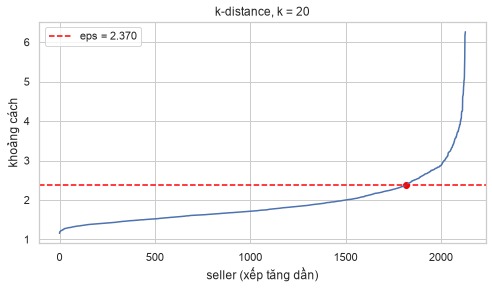

,min_samples,eps,eps_factor,cluster_sizes,n_clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,10,1.6593,0.7,[1683],1,0.2095,NaN,NaN,NaN,NaN
1,10,1.8964,0.8,[1871],1,0.1212,NaN,NaN,NaN,NaN
2,10,2.1334,0.9,[1981],1,0.0695,NaN,NaN,NaN,NaN
3,10,2.3705,1.0,[2047],1,0.0385,NaN,NaN,NaN,NaN
4,10,2.6075,1.1,[2080],1,0.0230,NaN,NaN,NaN,NaN
5,10,2.8446,1.2,[2101],1,0.0132,NaN,NaN,NaN,NaN
6,10,3.3187,1.4,[2117],1,0.0056,NaN,NaN,NaN,NaN
7,20,1.6593,0.7,[1555],1,0.2696,NaN,NaN,NaN,NaN
8,20,1.8964,0.8,[1802],1,0.1536,NaN,NaN,NaN,NaN
9,20,2.1334,0.9,[1931],1,0.0930,NaN,NaN,NaN,NaN


In [18]:
MIN_SAMPLES = 2 * X.shape[1]
# kneighbors trên chính X tính cả điểm đó, khớp định nghĩa core point của DBSCAN (min_samples gồm cả chính nó)
dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
i = np.arange(len(dist))
line = dist[0] + (dist[-1] - dist[0]) * i / (len(dist) - 1)
knee = int(np.argmax(line - dist))
EPS = float(dist[knee])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(i, dist); ax.axhline(EPS, color="red", ls="--", label=f"eps = {EPS:.3f}")
ax.scatter([knee], [EPS], color="red")
ax.set(title=f"k-distance, k = {MIN_SAMPLES}", xlabel="seller (xếp tăng dần)", ylabel="khoảng cách"); ax.legend()
save(fig, "dbscan_kdistance.png")

db_rows = []
for ms in [MIN_SAMPLES // 2, MIN_SAMPLES, MIN_SAMPLES * 3 // 2]:
    for f in [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.4]:
        lab = DBSCAN(eps=EPS * f, min_samples=ms).fit_predict(X)
        sizes = np.unique(lab[lab >= 0], return_counts=True)[1]
        db_rows.append({"min_samples": ms, "eps": EPS * f, "eps_factor": f, "cluster_sizes": sizes.tolist()} | scores(lab))
db_metrics = pd.DataFrame(db_rows)
db_metrics.to_csv(OUT / "dbscan_metrics.csv", index=False)
db_metrics.round(4)

In [19]:
db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X)
db_labels = relabel(db_labels)
print(f"DBSCAN eps={EPS:.3f}, min_samples={MIN_SAMPLES}: cụm {np.bincount(db_labels[db_labels >= 0]).tolist()}, "
      f"nhiễu {(db_labels == -1).sum()} seller ({(db_labels == -1).mean():.1%})")

noise = pd.DataFrame({"nhom": np.where(db_labels == -1, "nhiễu", "trong cụm")}).join(df[FEATURES + ["total_sales"]])
cmp = noise.groupby("nhom")[FEATURES].median().T
cmp["chenh_lech_chuan_hoa"] = pd.DataFrame(X, columns=FEATURES).groupby(noise["nhom"]).mean().T.diff(axis=1).iloc[:, -1]
print("Tỷ trọng doanh số của nhóm nhiễu:", round(noise.loc[noise.nhom == "nhiễu", "total_sales"].sum() / noise.total_sales.sum(), 4))
cmp.round(3)

DBSCAN eps=2.370, min_samples=20: cụm [2019], nhiễu 110 seller (5.2%)
Tỷ trọng doanh số của nhóm nhiễu: 0.0665


nhom,nhiễu,trong cụm,chenh_lech_chuan_hoa
order_count,5.000,13.000,0.672
recency_days,101.500,27.000,-0.581
tenure_days,329.000,329.000,-0.017
late_delivery_rate,0.167,0.031,-1.575
review_score_mean,3.536,4.250,1.582
category_count,1.000,2.000,0.424
avg_ship_distance_km,528.772,564.494,0.430
delivery_days_mean,17.010,11.222,-1.015
price_index,2.795,0.904,-1.574
freight_per_item,32.685,18.257,-1.430


## 7. So sánh 3 thuật toán

Metric tính trên cùng ma trận `X`. Với DBSCAN, metric chỉ tính trên các điểm không phải nhiễu, nên không so trực tiếp được với hai thuật toán kia nếu tỷ lệ nhiễu lớn.

In [20]:
models = {f"K-Means k={K_KMEANS}": km_labels, f"GMM {GMM_COV} k={GMM_K}": gmm_labels,
          f"GMM {gm5.iloc[0]['covariance']} k={K_KMEANS}": gmm5_labels, f"DBSCAN eps={EPS:.2f}": db_labels}
compare = pd.DataFrame({name: scores(lab) | {"cluster_sizes": np.unique(lab[lab >= 0], return_counts=True)[1].tolist()}
                        for name, lab in models.items()}).T
compare.to_csv(OUT / "model_comparison.csv")
display(compare)
names = list(models)
ari = pd.DataFrame([[adjusted_rand_score(models[a], models[b]) for b in names] for a in names], index=names, columns=names)
print("ARI giữa các mô hình (nhiễu DBSCAN tính là một nhãn riêng):")
ari.round(3)

,n_clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,cluster_sizes
K-Means k=5,5,0.0,0.168878,1.605225,356.226833,0.100986,"[539, 274, 526, 575, 215]"
GMM full k=7,7,0.0,0.027274,2.74544,146.670286,0.057774,"[299, 343, 274, 740, 123, 159, 191]"
GMM full k=5,5,0.0,0.06302,2.51713,176.180202,0.055895,"[547, 314, 923, 119, 226]"
DBSCAN eps=2.37,1,0.051667,NaN,NaN,NaN,NaN,[2019]


ARI giữa các mô hình (nhiễu DBSCAN tính là một nhãn riêng):


,K-Means k=5,GMM full k=7,GMM full k=5,DBSCAN eps=2.37
K-Means k=5,1.000,0.257,0.266,0.027
GMM full k=7,0.257,1.000,0.617,0.012
GMM full k=5,0.266,0.617,1.000,0.038
DBSCAN eps=2.37,0.027,0.012,0.038,1.000


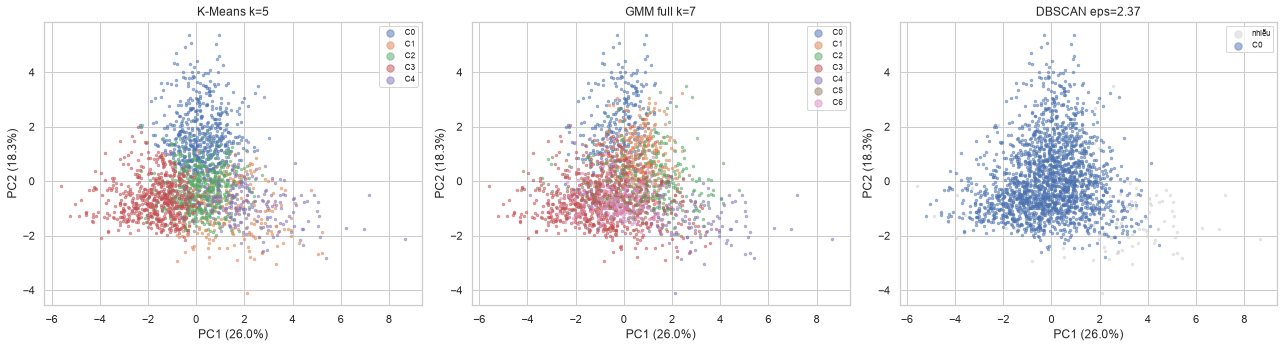

PCA 2D chỉ giữ 44.3% phương sai: cụm chồng lên nhau trên hình chưa chắc chồng lấn trong 10 chiều. Tải trọng:


,PC1,PC2
review_score_mean,-0.336,-0.030
category_count,0.024,0.547
order_count,0.070,0.650
recency_days,0.233,-0.284
price_index,0.291,-0.186
tenure_days,0.300,0.337
freight_per_item,0.336,-0.212
late_delivery_rate,0.346,-0.035
avg_ship_distance_km,0.353,0.012
delivery_days_mean,0.544,0.053


In [21]:
pca = PCA(2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
ev = pca.explained_variance_ratio_
pca_models = {n: l for n, l in models.items() if n != f"GMM {gm5.iloc[0]['covariance']} k={K_KMEANS}" or GMM_K == K_KMEANS}
fig, ax = plt.subplots(1, len(pca_models), figsize=(6 * len(pca_models), 5))
for a, (name, lab) in zip(ax, pca_models.items()):
    for c in np.unique(lab):
        m = lab == c
        a.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, label="nhiễu" if c == -1 else f"C{c}", c="lightgray" if c == -1 else None)
    a.set(title=name, xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})"); a.legend(markerscale=3, fontsize=8)
fig.tight_layout()
save(fig, "pca_3_methods.png")
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
print(f"PCA 2D chỉ giữ {ev.sum():.1%} phương sai: cụm chồng lên nhau trên hình chưa chắc chồng lấn trong 10 chiều. Tải trọng:")
load.round(3).sort_values("PC1")

## 8. Profile cụm của K-Means

Bảng trung vị trên thang gốc, cộng thêm các cột chỉ dùng mô tả (doanh số, giá trị đơn, `hot_score`, tỷ lệ khác bang, tỷ lệ hủy, khách quay lại). Radar chart vẽ trung vị z-score (sau `log1p` và chuẩn hóa) của từng cụm trên **cùng một thang** cho mọi trục: 0 là trung bình cohort, ±1 là một độ lệch chuẩn. Khác biệt nhỏ hiện ra nhỏ, không bị phóng đại.

In [22]:
P_df = df.assign(cluster=km_labels)
prof = P_df.groupby("cluster")[FEATURES + DESCRIBE].median()
prof.insert(0, "sales_share", P_df.groupby("cluster")["total_sales"].sum() / P_df["total_sales"].sum())
prof.insert(0, "n_sellers", P_df.groupby("cluster").size())
prof["late_delivery_rate_mean"] = P_df.groupby("cluster")["late_delivery_rate"].mean()
prof["review_score_mean_mean"] = P_df.groupby("cluster")["review_score_mean"].mean()
prof["cancel_rate_mean"] = P_df.groupby("cluster")["cancel_rate"].mean()
prof["pct_sp"] = P_df.groupby("cluster")["seller_state"].apply(lambda s: (s == "SP").mean())
prof["top_region"] = P_df.groupby("cluster")["seller_region"].agg(lambda s: s.value_counts().index[0])
prof.to_csv(OUT / "kmeans_cluster_profile.csv")
prof.T

cluster,0,1,2,3,4
n_sellers,539,274,526,575,215
sales_share,0.676445,0.158378,0.075613,0.057229,0.032336
order_count,74.0,11.0,9.0,7.0,7.0
recency_days,11.0,31.0,207.0,15.0,108.0
tenure_days,478.0,296.5,485.5,119.0,312.0
late_delivery_rate,0.056911,0.024448,0.0,0.0,0.25
review_score_mean,4.180851,4.272727,4.292659,4.454545,3.571429
category_count,4.0,2.0,2.0,2.0,1.0
avg_ship_distance_km,578.22874,745.401015,586.04301,440.311189,620.041944
delivery_days_mean,12.268237,12.800526,11.828494,7.89456,18.208133


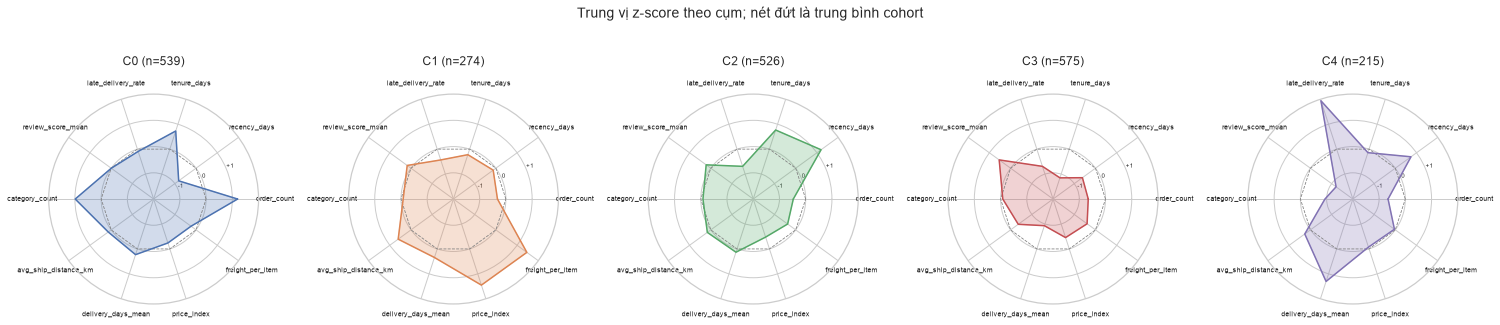

In [23]:
rad = pd.DataFrame(X, columns=FEATURES).groupby(km_labels).median()
LIM = float(np.ceil(rad.abs().max().max() * 2) / 2)
ang = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
fig, axes = plt.subplots(1, K_KMEANS, figsize=(4.2 * K_KMEANS, 4.5), subplot_kw={"polar": True})
for a, (c, row) in zip(axes, rad.iterrows()):
    v = row.tolist()
    a.plot(ang + ang[:1], [0] * (len(ang) + 1), color="gray", lw=0.8, ls="--")
    a.plot(ang + ang[:1], v + v[:1], color=f"C{c}"); a.fill(ang + ang[:1], v + v[:1], alpha=0.25, color=f"C{c}")
    a.set_xticks(ang); a.set_xticklabels(FEATURES, fontsize=7); a.set_ylim(-LIM, LIM)
    a.set_yticks([-1, 0, 1]); a.set_yticklabels(["-1", "0", "+1"], fontsize=6)
    a.set_title(f"C{c} (n={int((km_labels == c).sum())})", pad=15)
fig.suptitle("Trung vị z-score theo cụm; nét đứt là trung bình cohort", y=1.03)
fig.tight_layout()
save(fig, "kmeans_radar.png")

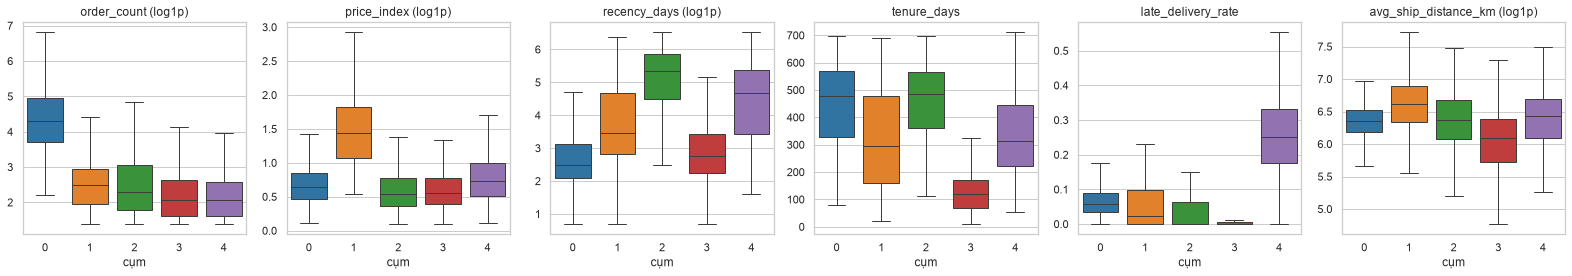

In [24]:
key = ["order_count", "price_index", "recency_days", "tenure_days", "late_delivery_rate", "avg_ship_distance_km"]
fig, axes = plt.subplots(1, len(key), figsize=(22, 4))
for a, c in zip(axes, key):
    sns.boxplot(x=km_labels, y=Xt[c], ax=a, showfliers=False, hue=km_labels, palette="tab10", legend=False)
    a.set(title=c + (" (log1p)" if c in LOG1P else ""), xlabel="cụm", ylabel="")
fig.tight_layout()
save(fig, "kmeans_boxplots.png")

In [25]:
assign = df[["seller_id", "seller_state", "seller_region"]].assign(kmeans=km_labels, gmm=gmm_labels, gmm_k5=gmm5_labels,
                                                                  gmm_max_proba=proba, dbscan=db_labels)
assign.to_csv(OUT / "seller_assignments.csv", index=False)
summary = {"n_sellers": len(df), "features": FEATURES, "kmeans": {"k": K_KMEANS, "k_by_rule": k_rule} | {k: float(v) for k, v in scores(km_labels).items()},
           "gmm": {"covariance": GMM_COV, "k": GMM_K} | {k: float(v) for k, v in scores(gmm_labels).items()},
           "dbscan": {"eps": EPS, "min_samples": MIN_SAMPLES} | {k: float(v) for k, v in scores(db_labels).items()},
           "pca_explained_variance": ev.tolist(), "kmeans_seed_ari_min": float(min(aris))}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_kdistance.png', 'dbscan_metrics.csv', 'eda_categorical.png', 'eda_cohort.png', 'eda_correlation.png', 'eda_distributions.png', 'eda_dropped_features.png', 'eda_pairplot.png', 'feature_stats_raw.csv', 'gmm_metrics.csv', 'gmm_selection.png', 'kmeans_boxplots.png', 'kmeans_cluster_profile.csv', 'kmeans_metrics.csv', 'kmeans_radar.png', 'kmeans_selection.png', 'kmeans_silhouette_samples.png', 'model_comparison.csv', 'model_input.csv', 'pca_3_methods.png', 'preprocessing.json', 'seller_assignments.csv', 'summary.json', 'unused_feature_screening.csv']


In [26]:
# Kiểm tra các số chính được viết tay ở mục 9; lệch thì sửa mục 9
km_s, gm_s = scores(km_labels), scores(gmm_labels)
prof_ = P_df.groupby("cluster")
checks = {
    "k theo metric = 5": k_rule == K_KMEANS,
    "K-Means silhouette 0,169": round(km_s["silhouette"], 3) == 0.169,
    "K-Means ARI seed nhỏ nhất 0,984": round(min(aris), 3) == 0.984,
    "kích thước cụm 539/274/526/575/215": np.bincount(km_labels).tolist() == [539, 274, 526, 575, 215],
    "GMM full k=7": (GMM_COV, GMM_K) == ("full", 7),
    "DBSCAN 1 cụm, 110 nhiễu": scores(db_labels)["n_clusters"] == 1 and int((db_labels == -1).sum()) == 110,
    "C1 price_index 3,25": round(prof_["price_index"].median()[1], 2) == 3.25,
    "C4 tỷ lệ trễ TB 26,3%": round(prof_["late_delivery_rate"].mean()[4], 3) == 0.263,
}
failed = [k for k, ok in checks.items() if not ok]
assert not failed, f"Số liệu đã đổi, cần sửa mục 9: {failed}"
print(f"{len(checks)} kiểm tra khớp với mục 9")

8 kiểm tra khớp với mục 9


## 9. Kết luận

Các con số dưới đây lấy từ output của notebook (`random_state=42`). Cell ngay trên kiểm tra các số chính; nếu chạy lại ra khác, cell đó báo lỗi và phải sửa mục này.

### 9.1. So sánh 3 thuật toán

| Mô hình | Số cụm | Silhouette | Davies-Bouldin | Calinski-Harabasz | Nhận xét |
|---|---:|---:|---:|---:|---|
| **K-Means k=5** | 5 | **0,169** | **1,61** | **356** | Tốt nhất cả 3 metric, ổn định qua 10 seed (ARI nhỏ nhất 0,984) |
| GMM full k=7 (BIC nhỏ nhất) | 7 | 0,027 | 2,75 | 147 | BIC chọn nhiều cụm nhưng các cụm gần như không tách |
| GMM full k=5 | 5 | 0,063 | 2,52 | 176 | Cùng k nhưng kém K-Means ở mọi metric; ARI với K-Means 0,27 |
| DBSCAN eps=2,37, min_samples=20 | 1 + nhiễu | - | - | - | Một cụm 2.019 seller và 110 seller nhiễu (5,2%) |

1. **K-Means được chọn.** k=5 vừa là lựa chọn nghiệp vụ vừa có silhouette lớn nhất trong k từ 2 đến 10 (k=4: 0,155; k=6: 0,155). Silhouette 0,169 vẫn thấp: các cụm chồng lấn, nhất là C1 (28,1% seller có silhouette âm) và C4 (28,8%). Nên hiểu các cụm là các vùng của một phổ liên tục, ranh giới giữa chúng không sắc nét.
2. **GMM kém hơn K-Means.** BIC phạt số tham số chứ không đo mức tách cụm, nên mô hình BIC tốt nhất (k=7) lại có silhouette thấp nhất.
3. **DBSCAN không tìm được cụm.** Trên toàn lưới thử (eps từ 0,7 đến 1,4 lần điểm khuỷu, min_samples 10, 20, 30), luôn chỉ có 1 cụm cộng nhiễu: dữ liệu seller không có vùng mật độ tách biệt. DBSCAN được dùng để **phát hiện ngoại lệ**: 110 seller nhiễu có trung vị tỷ lệ giao trễ 0,17 (trong cụm 0,03), review 3,54 (trong cụm 4,25), `price_index` 2,80 (trong cụm 0,90).

### 9.2. Phân khúc và đề xuất chính sách (K-Means k=5)

Cụm đánh số theo tổng doanh số giảm dần. Giá trị là trung vị, trừ tỷ lệ giao trễ và review là trung bình.

| Cụm | Seller | Doanh số | Đặc điểm | Tên phân khúc | Chính sách đề xuất |
|---|---:|---:|---|---|---|
| C0 | 539 | 67,6% | 74 đơn, 4 ngành, khách ở 14 bang, bán gần nhất 11 ngày trước | Chủ lực đa ngành | Giữ chân: ưu đãi phí sàn, hỗ trợ ưu tiên |
| C1 | 274 | 15,8% | `price_index` 3,25, giá trị đơn 385 BRL, phí ship 38 BRL/món, cách khách 745 km | Giá cao, giao xa | Giảm chi phí giao xa: trợ giá phí ship liên bang |
| C2 | 526 | 7,6% | 207 ngày không bán, đã bán 486 ngày | Ngưng hoạt động | Kích hoạt lại: liên hệ, khuyến mãi quay lại |
| C3 | 575 | 5,7% | Bắt đầu bán 119 ngày, giao 7,9 ngày, cách khách 440 km, review 4,40 | Mới, bán gần | Hỗ trợ seller mới mở rộng ra ngoài bang |
| C4 | 215 | 3,2% | Tỷ lệ trễ 26,3%, review 3,49, giao 18,2 ngày | Giao trễ, review thấp | Kiểm soát chất lượng: cảnh báo, ràng buộc thời gian giao |

`hot_score`, `interstate_rate`, `cancel_rate` và `repeat_customer_rate` không vào mô hình, chỉ dùng để mô tả. `cancel_rate` và `repeat_customer_rate` có trung vị 0 ở mọi cụm.

Chính sách là đề xuất suy từ profile cụm, chưa có số liệu chi phí hay hiệu quả để kiểm chứng.

### 9.3. Hạn chế

1. Đặc trưng tính từ CSV thô Kaggle (`mining/seller_features_extended.py`), chưa đọc từ kho `OlistDW`.
2. Review và ngày giao thuộc cả đơn; đơn nhiều seller dùng chung giá trị.
3. Phân cụm mô tả dữ liệu lịch sử, không đánh giá dự báo.
4. Chỉ seller có từ 3 đơn delivered (2.129 seller, 98% doanh số) được phân cụm.